# 04 — Visualizations (uni / bi / multivariate)

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 110

conn = sqlite3.connect("data/tmdb.db")
movies = pd.read_sql("SELECT * FROM movies", conn)
genres = pd.read_sql("SELECT * FROM genres", conn)
mg     = pd.read_sql("SELECT * FROM movie_genres", conn)
movies["release_date"] = pd.to_datetime(movies["release_date"], errors="coerce")
movies["release_year"] = movies["release_date"].dt.year

primary = pd.read_csv("data/movie_genres.csv").groupby("movie_id").first().reset_index().merge(genres, on="genre_id")[["movie_id", "genre_name"]]

## Univariate

### 1. Budget distribution

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(movies.loc[movies.budget > 0, "budget"] / 1e6, bins=50, kde=True, ax=ax)
ax.set_title("Distribution of movie budgets (non-zero)")
ax.set_xlabel("Budget (million USD)")
plt.tight_layout(); plt.show()

<Figure size 1100x550 with 1 Axes>

**Insight:** Budgets are heavily right-skewed — most films are under $50M,
with a small tail of $200M+ tentpoles.

### 2. Runtime distribution

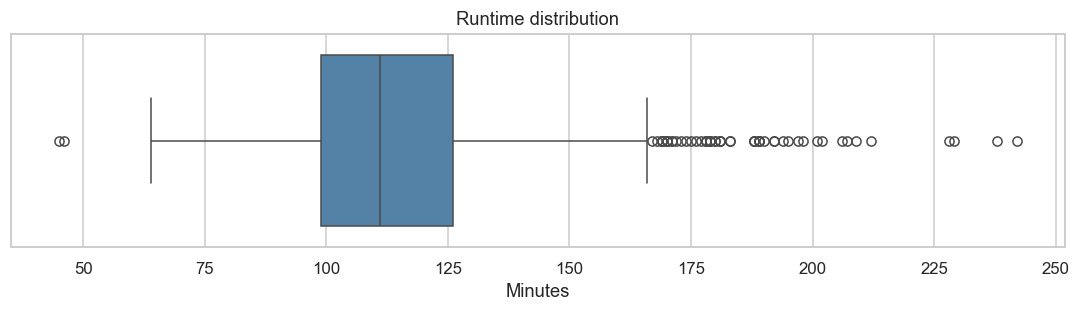

In [3]:
fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=movies.runtime.dropna(), ax=ax, color="steelblue")
ax.set_title("Runtime distribution"); ax.set_xlabel("Minutes")
plt.tight_layout(); plt.show()

**Insight:** The median runtime is ~100 min with a tight IQR; outliers are
long-form epics rather than data errors.

### 3. Rating distribution

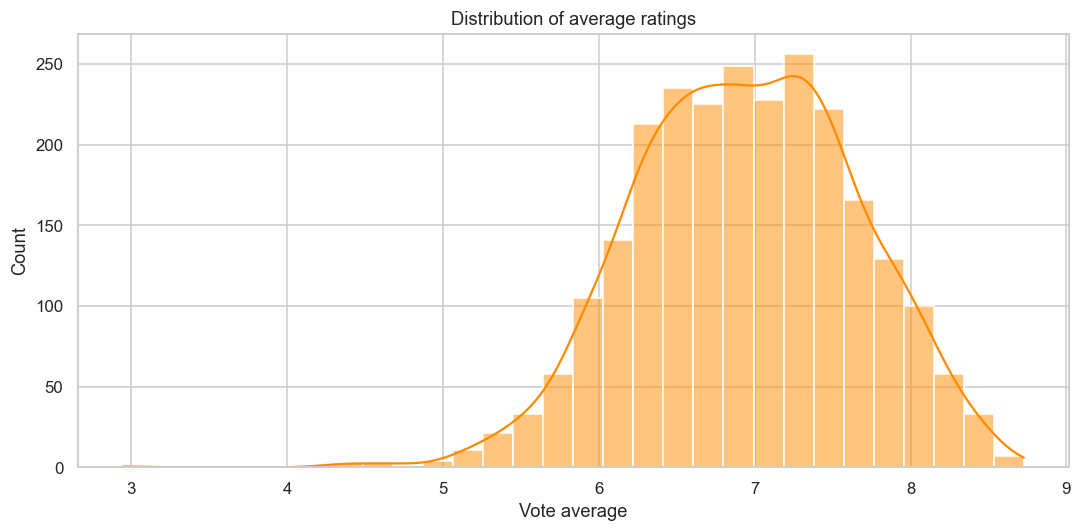

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(movies.vote_average.dropna(), bins=30, kde=True, ax=ax, color="darkorange")
ax.set_title("Distribution of average ratings"); ax.set_xlabel("Vote average")
plt.tight_layout(); plt.show()

**Insight:** Ratings cluster around 6–7 — a typical "slightly positive" bias
for released films that gather votes.

### 4. Movies per genre

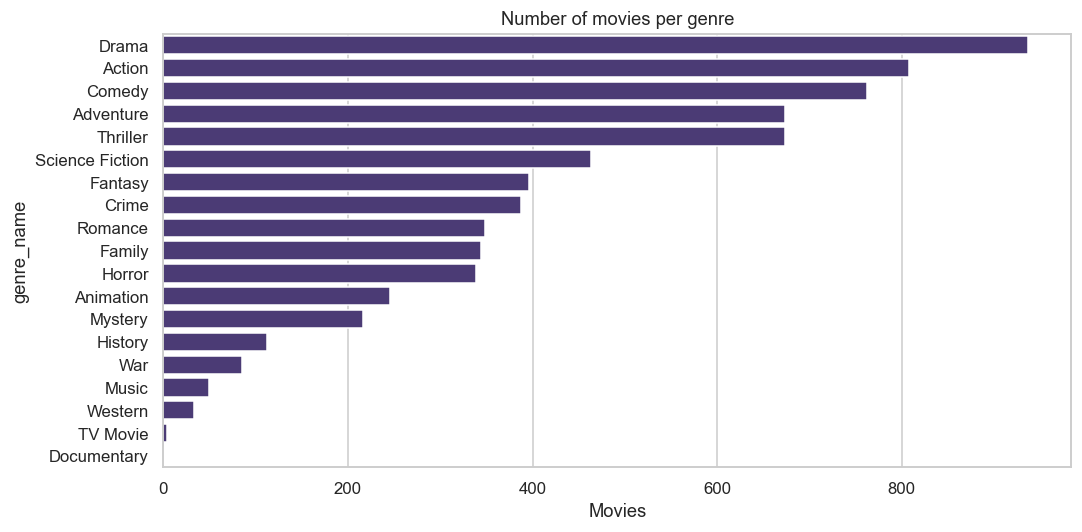

In [5]:
gc = mg.merge(genres, on="genre_id").groupby("genre_name").size().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=gc.values, y=gc.index, ax=ax)
ax.set_title("Number of movies per genre"); ax.set_xlabel("Movies")
plt.tight_layout(); plt.show()

**Insight:** Drama, Comedy and Thriller dominate the catalogue — the
workhorse genres of mainstream cinema.

## Bivariate

### 5. Budget vs revenue

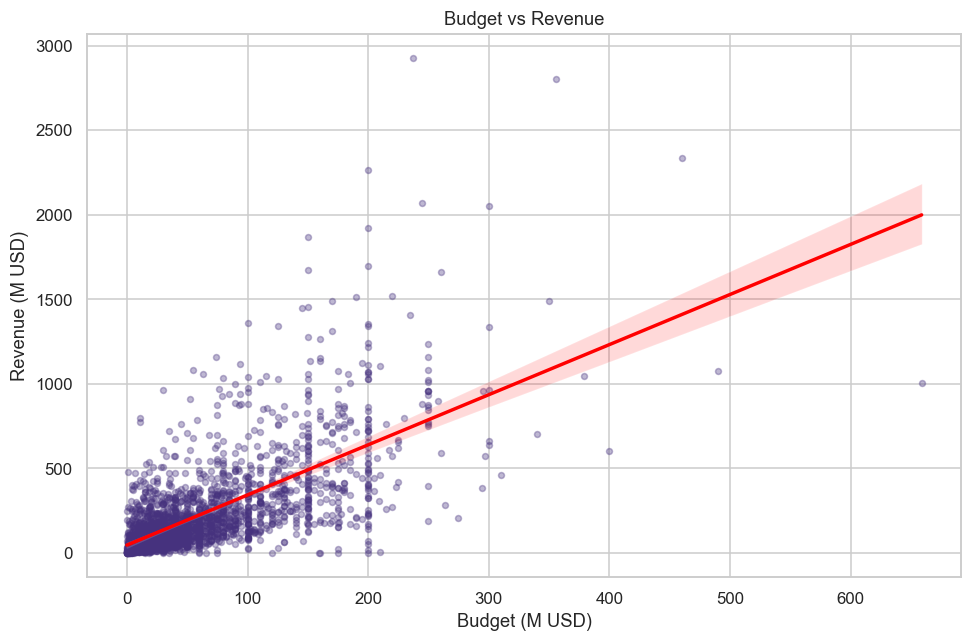

In [6]:
sub = movies[(movies.budget > 0) & (movies.revenue > 0)]
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(x=sub.budget/1e6, y=sub.revenue/1e6, ax=ax,
            scatter_kws={"alpha": 0.35, "s": 15}, line_kws={"color": "red"})
ax.set_title("Budget vs Revenue"); ax.set_xlabel("Budget (M USD)"); ax.set_ylabel("Revenue (M USD)")
plt.tight_layout(); plt.show()

**Insight:** A strong positive linear relationship confirms that bigger budgets
generally earn more — but variance is huge, meaning budget is a weak predictor
of individual outcomes.

### 6. Popularity vs vote count

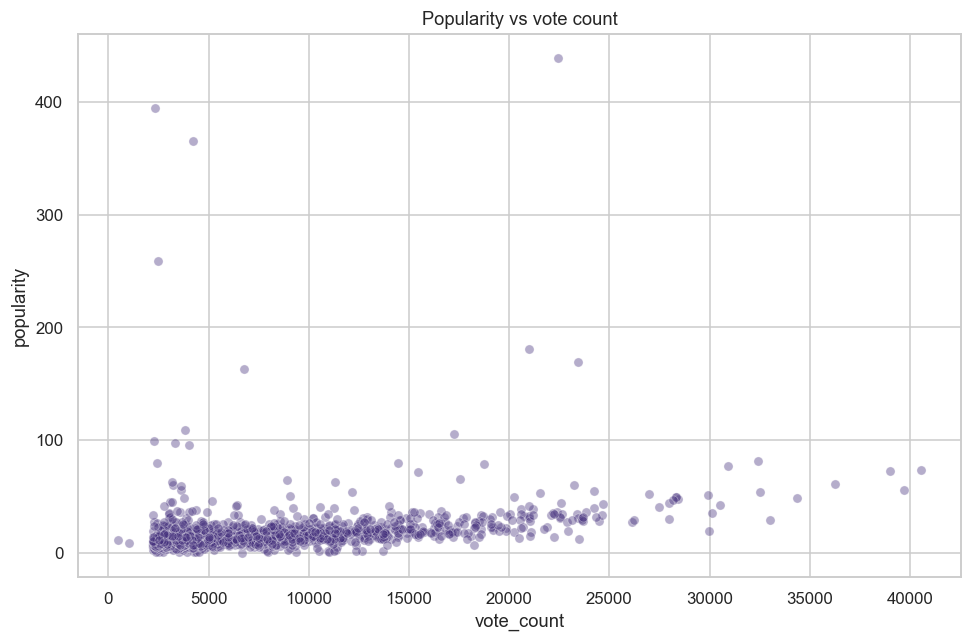

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=movies, x="vote_count", y="popularity", alpha=0.4, ax=ax)
ax.set_title("Popularity vs vote count")
plt.tight_layout(); plt.show()

**Insight:** Positive correlation with a few high-popularity outliers — those
are recently trending titles that haven't yet accumulated votes.

### 7. Average rating by genre

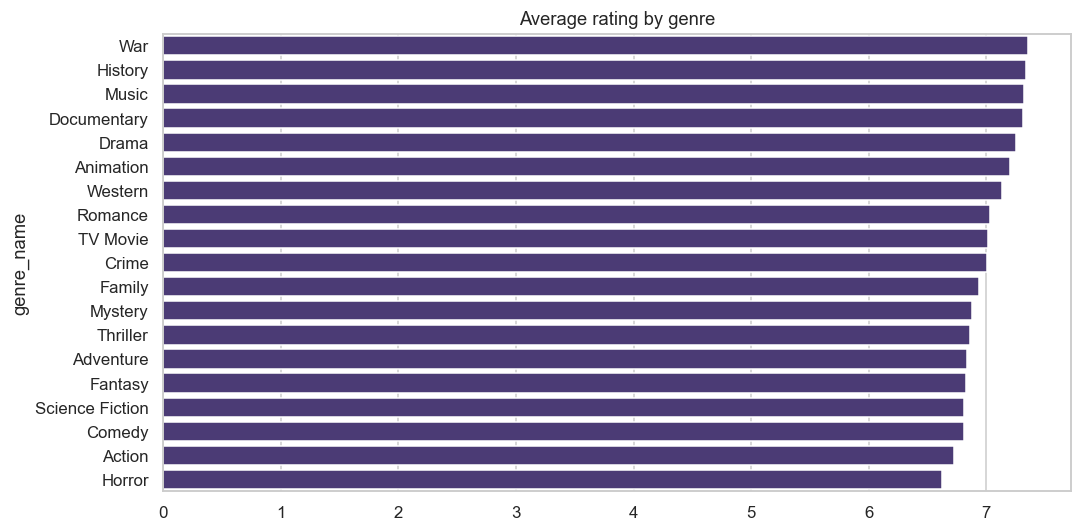

In [8]:
ar = mg.merge(movies[["movie_id", "vote_average"]], on="movie_id").merge(genres, on="genre_id").groupby("genre_name").vote_average.mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=ar.values, y=ar.index, ax=ax)
ax.set_title("Average rating by genre")
plt.tight_layout(); plt.show()

**Insight:** Documentaries and History command the highest average ratings,
while Horror and TV Movie rank lowest.

### 8. Movies released per year

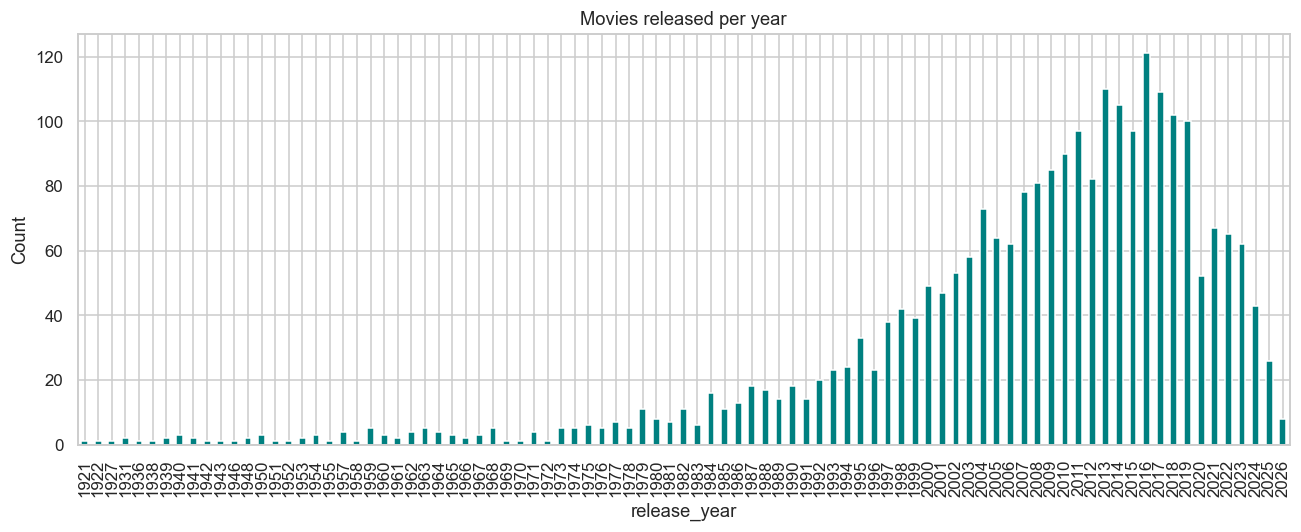

In [9]:
py = movies.dropna(subset=["release_year"]).groupby("release_year").size()
fig, ax = plt.subplots(figsize=(12, 5))
py.plot(kind="bar", ax=ax, color="teal")
ax.set_title("Movies released per year"); ax.set_ylabel("Count")
plt.tight_layout(); plt.show()

**Insight:** Output rises sharply after 2000 — recent decades dominate the dataset,
so historical comparisons should use normalised metrics.

## Multivariate

### 9. Correlation heatmap (budget, revenue, runtime, popularity, vote_average, vote_count)

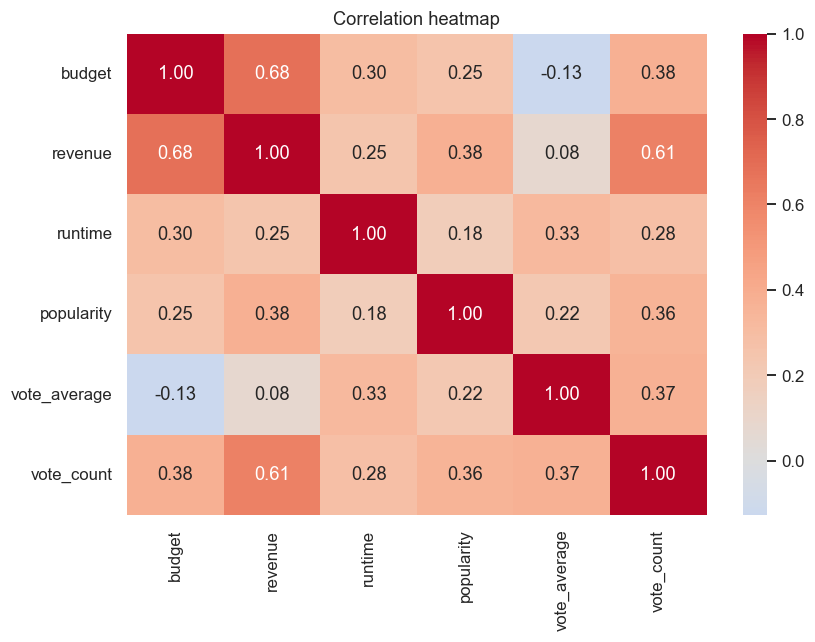

In [10]:
cols = ["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]
corr = movies[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation heatmap")
plt.tight_layout(); plt.show()

**Insight:** Budget–revenue is the strongest pair (~0.7). Vote count also tracks
revenue closely, while runtime is nearly independent of financials.

### 10. Pairplot of budget, revenue, popularity, vote_average — colored by primary genre

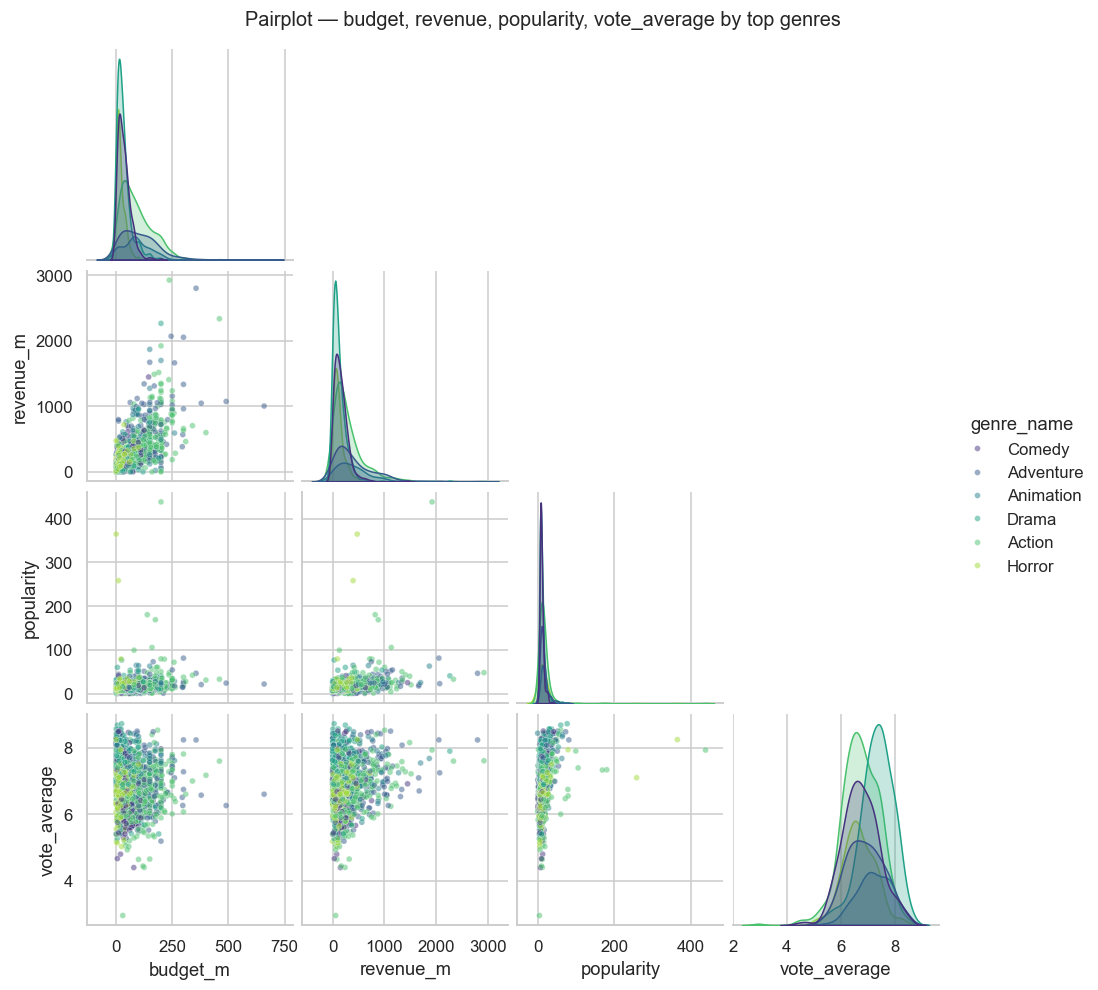

In [11]:
pair_df = (
    movies[["movie_id", "budget", "revenue", "popularity", "vote_average"]]
    .merge(primary, on="movie_id", how="left")
)
pair_df["genre_name"] = pair_df["genre_name"].fillna("Unknown")

# Keep top 6 genres so colours stay readable, and drop uninformative zeros
top6 = pair_df["genre_name"].value_counts().head(6).index.tolist()
pair_df = pair_df[pair_df["genre_name"].isin(top6)]
pair_df = pair_df[(pair_df["budget"] > 0) & (pair_df["revenue"] > 0)]

# Scale money columns to millions for readable axes
pair_df["budget_m"]  = pair_df["budget"] / 1e6
pair_df["revenue_m"] = pair_df["revenue"] / 1e6

g = sns.pairplot(
    pair_df[["budget_m", "revenue_m", "popularity", "vote_average", "genre_name"]],
    hue="genre_name",
    corner=True,
    plot_kws={"s": 15, "alpha": 0.5},
    diag_kind="kde",
    height=2.2,
)
g.fig.suptitle("Pairplot — budget, revenue, popularity, vote_average by top genres",
               y=1.02, fontsize=13)
plt.show()

**Insight:** Budget and revenue show a clear positive diagonal across almost every
genre, but the correlation strength varies — Animation and Adventure sit higher on
the revenue axis for the same budget, while Drama and Comedy spread more widely.
Vote average appears largely independent of financials, confirming that money
does not buy critical reception.

### 11. Budget vs revenue, colored by primary genre, size = vote_count

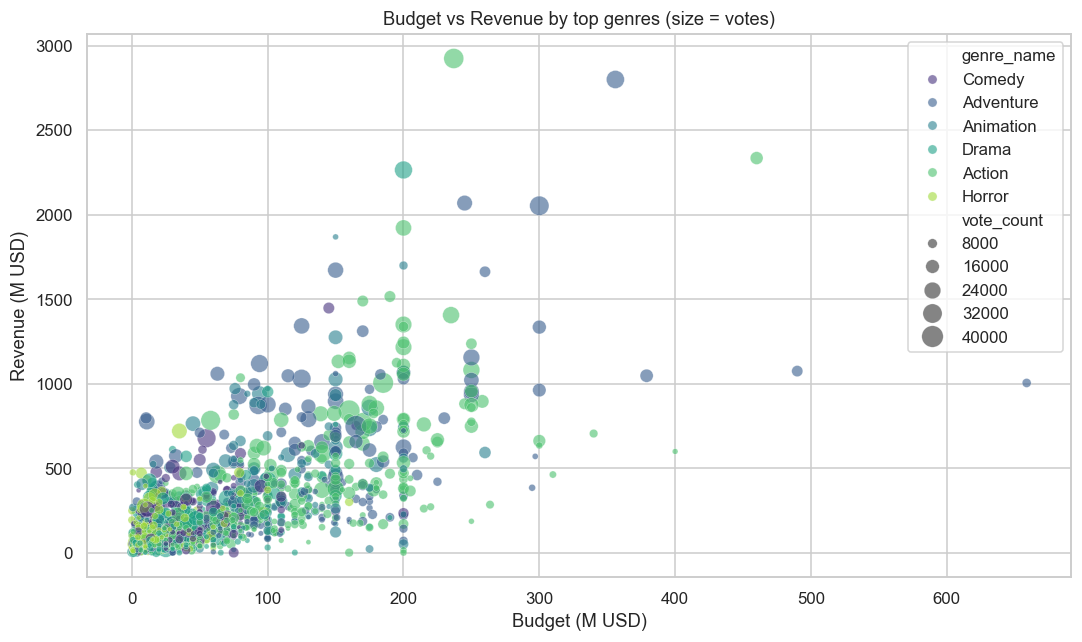

In [12]:
sub2 = sub.merge(primary, on="movie_id", how="left")
sub2["genre_name"] = sub2["genre_name"].fillna("Unknown")
top_g = sub2.genre_name.value_counts().head(6).index
sub2 = sub2[sub2.genre_name.isin(top_g)]
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=sub2, x=sub2.budget/1e6, y=sub2.revenue/1e6,
                hue="genre_name", size="vote_count", sizes=(10, 200), alpha=0.6, ax=ax)
ax.set_title("Budget vs Revenue by top genres (size = votes)")
ax.set_xlabel("Budget (M USD)"); ax.set_ylabel("Revenue (M USD)")
plt.tight_layout(); plt.show()

**Insight:** Animation and Adventure films cluster in the high-revenue region,
while Drama spans the entire budget range with mixed returns. Large bubbles
(high vote_count) skew toward high-revenue films — big-budget hits also tend
to be the most-watched.

### 12. Distribution of vote_average per genre (FacetGrid of histograms)

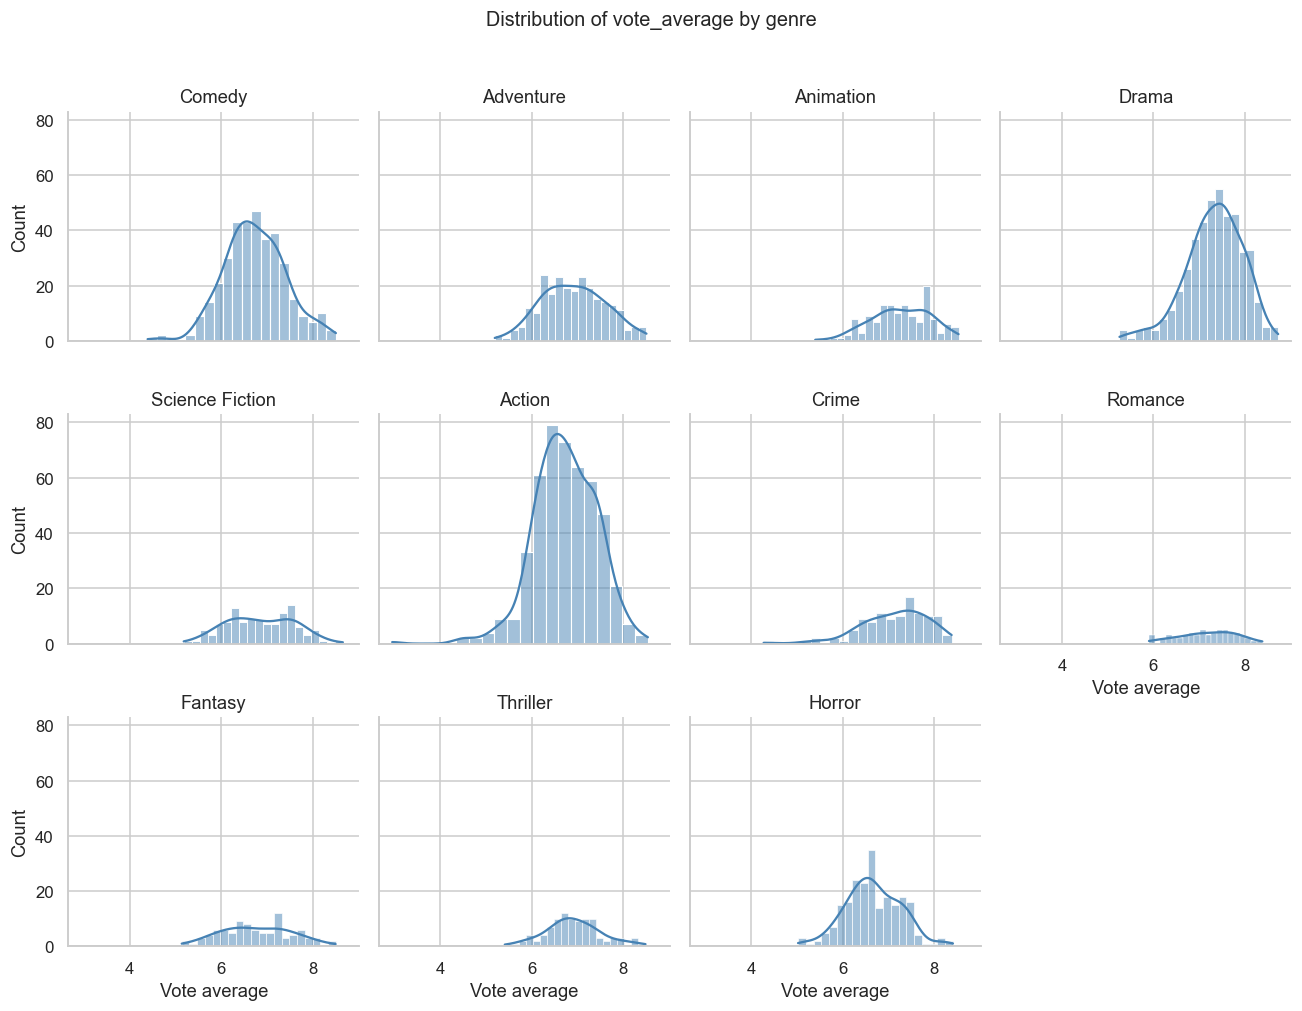

In [13]:
facet_df = (
    movies[["movie_id", "vote_average"]]
    .merge(primary, on="movie_id", how="left")
    .dropna(subset=["vote_average"])
)
facet_df["genre_name"] = facet_df["genre_name"].fillna("Unknown")

# Keep genres with enough data points so each panel is meaningful
keep = facet_df["genre_name"].value_counts()
keep = keep[keep >= 50].index.tolist()
facet_df = facet_df[facet_df["genre_name"].isin(keep)]

g = sns.FacetGrid(
    facet_df,
    col="genre_name",
    col_wrap=4,
    height=3,
    sharex=True,
    sharey=True,
)
g.map_dataframe(sns.histplot, x="vote_average", bins=20, kde=True, color="steelblue")
g.set_axis_labels("Vote average", "Count")
g.set_titles(col_template="{col_name}")
g.fig.suptitle("Distribution of vote_average by genre", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

**Insight:** Most genres peak around 6–7 on the rating scale, but the shape differs:
Documentary and History have tighter, right-shifted distributions (higher ratings,
less variance), while Horror and Comedy show wider spreads with longer left tails.
This suggests audiences are more consistent about documentaries and history films
than about genre fiction.

### 13. Average revenue by genre and release decade (pivot heatmap)

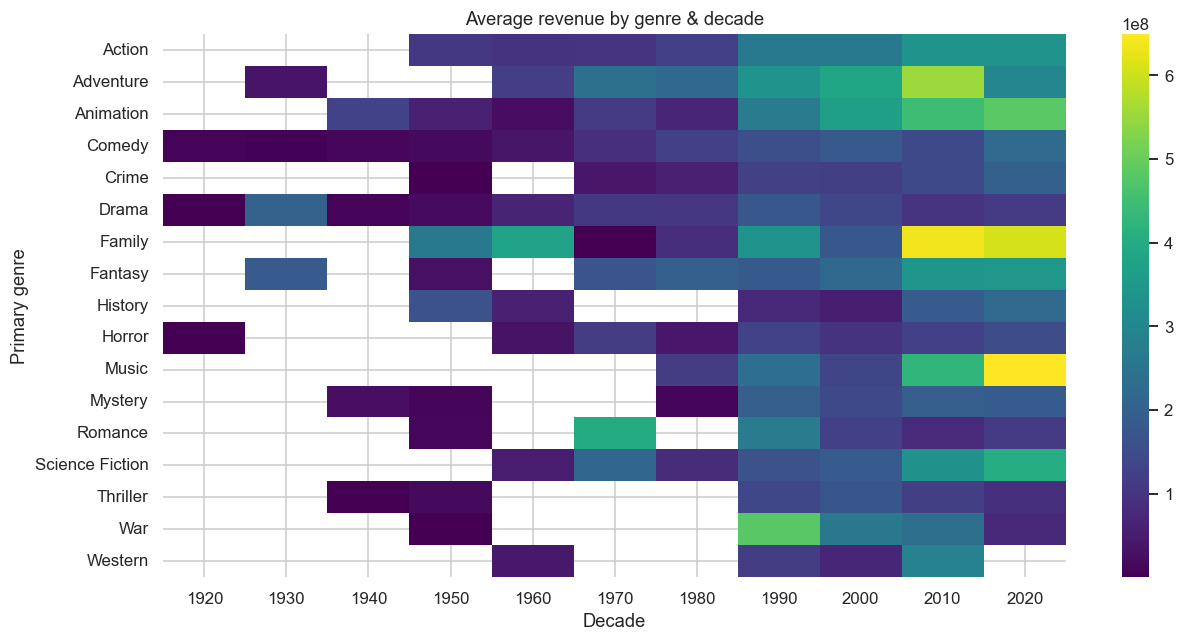

In [14]:
df = movies.merge(primary, on="movie_id", how="left").dropna(subset=["release_year", "revenue"])
df = df[df.revenue > 0].copy()
df["decade"] = (df.release_year // 10 * 10).astype(int)
pivot = df.pivot_table(index="genre_name", columns="decade", values="revenue", aggfunc="mean")
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(pivot, cmap="viridis", ax=ax)
ax.set_title("Average revenue by genre & decade")
ax.set_xlabel("Decade"); ax.set_ylabel("Primary genre")
plt.tight_layout(); plt.show()

**Insight:** Animation and Adventure revenues expanded dramatically in the 2010s,
while Drama and Comedy held steady — reflecting the rise of the global blockbuster.